In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_rows', None)
from pathlib import Path

In [147]:
dados_path = Path('data')
df_o = pd.read_excel(dados_path / 'Cópia 2 de [PT-BR] Script do Questionário (respostas) (1).xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

#print(df.columns.tolist())

95


In [148]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

['Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software'
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
(83, 102)


In [149]:
df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()]

,Carimbo de data/hora,"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",Qual é a sua idade?,Em qual estado do Brasil você mora atualmente?,Qual é o seu gênero?,Qual é o seu nível de educação formal concluída?,Qual seu modelo de trabalho?,Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,"Por favor, indique a senioridade da posição que ocupa.",Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,...,Em quais fases do ciclo de desenvolvimento de software você costuma utilizar as ferramentas de segurança automatizadas selecionadas na pergunta anterior? (Selecione todas as opções que se aplicam),Quais recomendações você daria para um desenvolvedor sobre a adoção de ferramentas de segurança para seus projetos?,Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam),Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam),"Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email.","Quais são as razões pelas quais você opta por não utilizar ferramentas automatizadas de segurança de software? Por favor, descreva brevemente sobre.",Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?,"Se você respondeu ""Sim"" ou ""Talvez"" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque ""Nenhuma"" se respondeu ""Não"".","Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email..1",Marque a imagem em que aparece um filhote de cachorro:


In [150]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

df = df.drop(df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()].index, axis=0)

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

0
0


In [151]:
#list(df.columns)

In [152]:
df['Qual é o seu nível de educação formal concluída?'].unique()

array(['Mestrado', 'Estudante de Doutorado', 'Ensino Superior',
       'Doutorado', 'Especialização', 'Ensino Médio',
       'Estudante de Mestrado'], dtype=object)

In [153]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [154]:
df.shape

(83, 102)

Peso

In [155]:
praticas = ['[Revisão de Código]',
            '[Modelagem de Ameaças]',
            '[Identificação de Casos de Abuso/Mau Uso]',
            '[Análise de Riscos Arquiteturais]',
            '[Testes de Penetração]',
            '[Gerenciamento de Riscos]',
            '[Gerenciamento de Vulnerabilidades]',
            '[Testes de Segurança Manuais/Automatizados]',
            '[Execução de Testes Fuzz]',
            '[Engenharia de Requisitos de Segurança]',
            '[Codificação Segura]',
            '[Resposta Emergencial ao Código]',
            '[Configurações e Gerenciamento de Segurança]',
            '[Monitoramento de Eventos de Segurança]',
            '[Auditorias de Segurança Externas]',
            '[Segurança da Cadeia de Suprimentos de Software]']

In [156]:
colunas_frequencia = [ 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Penetração]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Riscos]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Vulnerabilidades]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Segurança Manuais/Automatizados]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Execução de Testes Fuzz]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Engenharia de Requisitos de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Codificação Segura]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Resposta Emergencial ao Código]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Configurações e Gerenciamento de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Monitoramento de Eventos de Segurança]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Auditorias de Segurança Externas]',
    'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]'
]


In [157]:
colunas_facilidade = ['Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Revisão de Código]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Modelagem de Ameaças]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Identificação de Casos de Abuso/Mau Uso]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Análise de Riscos Arquiteturais]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Testes de Penetração]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Gerenciamento de Riscos]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Gerenciamento de Vulnerabilidades]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Testes de Segurança Manuais/Automatizados]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Execução de Testes Fuzz]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Engenharia de Requisitos de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Codificação Segura]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Resposta Emergencial ao Código]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Configurações e Gerenciamento de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Monitoramento de Eventos de Segurança]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Auditorias de Segurança Externas]',
            'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Segurança da Cadeia de Suprimentos de Software]'
]


In [158]:
colunas_efetividade = ['Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Penetração]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Riscos]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Gerenciamento de Vulnerabilidades]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Testes de Segurança Manuais/Automatizados]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Execução de Testes Fuzz]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Engenharia de Requisitos de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Codificação Segura]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Resposta Emergencial ao Código]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Configurações e Gerenciamento de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Monitoramento de Eventos de Segurança]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Auditorias de Segurança Externas]',
            'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]'
]

In [159]:
colunas_essencialidade = ['Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Revisão de Código]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Modelagem de Ameaças]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Identificação de Casos de Abuso/Mau Uso]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Análise de Riscos Arquiteturais]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Penetração]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Gerenciamento de Riscos]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Gerenciamento de Vulnerabilidades]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Segurança Manuais/Automatizados]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Execução de Testes Fuzz]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Engenharia de Requisitos de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Codificação Segura]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Resposta Emergencial ao Código]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Configurações e Gerenciamento de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Monitoramento de Eventos de Segurança]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Auditorias de Segurança Externas]',
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Segurança da Cadeia de Suprimentos de Software]']

In [160]:
frequencia_map = {
    'Não aplicável': 0,
    'Anualmente': 1,
    'Mensalmente': 2,
    'Semanalmente': 3,
    'Diariamente': 4,
}

efetividade_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

facilidade_map = {
    'Não Aplicável': 0,
    'Muito Baixo': 1,
    'Baixo': 2,
    'Moderado': 3,
    'Alto': 4,
    'Muito Alto': 5,
}

essencialidade_map = {
    'Discordo Totalmente': 1,
    'Discordo': 2,
    'Neutro': 3,
    'Concordo': 4,
    'Concordo Totalmente': 5,
}

In [161]:
def plot_barras(
    df_freq: pd.DataFrame,
    titulo: str = "Frequência das Práticas de Segurança",
    categorias: list = None
):
    """
    Cria um gráfico de barras horizontais empilhadas com as categorias de frequência.
    Detecta automaticamente as categorias presentes no DataFrame.
    """

    # Se categorias não forem passadas, usar as colunas do df
    if categorias is None:
        categorias = list(df_freq.columns)

    # Converter contagens em porcentagens
    df_pct = df_freq.div(df_freq.sum(axis=1), axis=0) * 100

    # Definir paleta adaptável (até 6 cores suaves)
    paleta_padrao = [
        "#cfcfcf", "#d4b483", "#b3cde3", "#8c96c6", "#5e4fa2", "#542788"
    ]
    cores = {cat: paleta_padrao[i % len(paleta_padrao)] for i, cat in enumerate(categorias)}

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    bottom = pd.Series([0] * len(df_pct), index=df_pct.index)

    for cat in categorias:
        if cat in df_pct.columns:
            ax.barh(df_pct.index, df_pct[cat], left=bottom, color=cores[cat], label=cat)
            bottom += df_pct[cat]

    # Estilo
    ax.set_xlabel("Percentual (%)")
    ax.set_ylabel("Atividade de Segurança")
    ax.set_title(titulo, fontsize=13, fontweight='bold', pad=15)
    ax.legend(
        title="Frequência",
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        frameon=False
    )
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()


In [162]:
def gerar_tabela_descricao(df: pd.DataFrame, ordem: list = None) -> pd.DataFrame:
    """
    Gera uma tabela de contagem de frequências para cada atividade de segurança.
    """
    desc_df = df.copy()

    # Ajustar nomes das colunas se estiverem no formato "coluna [x]"
    desc_df.columns = [c.split("[")[1].replace("]", "") if "[" in c else c for c in desc_df.columns]

    # Renomear caso necessário
    desc_df = desc_df.rename({"Revisão de Código": "Práticas de Segurança"}, axis=1)

    # Criar tabela de contagens
    descricao_frequencia = {}

    for col in desc_df.columns:
        # value_counts + reindex garante que TODAS as categorias aparecem
        counts = desc_df[col].value_counts().reindex(ordem, fill_value=0)
        descricao_frequencia[col] = counts

    # Criar DataFrame final
    descricao_frequencia = pd.DataFrame(descricao_frequencia).T

    return descricao_frequencia.astype(int)

descricao_frequencia = gerar_tabela_descricao(df[colunas_frequencia], ordem=frequencia_map.keys())
descricao_facilidade = gerar_tabela_descricao(df[colunas_facilidade], ordem=facilidade_map.keys())
descricao_efetividade = gerar_tabela_descricao(df[colunas_efetividade], ordem=efetividade_map.keys())
descricao_essencialidade = gerar_tabela_descricao(df[colunas_essencialidade], ordem=essencialidade_map.keys())

In [163]:
descricao_frequencia = descricao_frequencia.rename({'Práticas de Segurança': 'Revisão de Código'})
descricao_facilidade = descricao_facilidade.rename({'Práticas de Segurança': 'Revisão de Código'})
descricao_efetividade = descricao_efetividade.rename({'Práticas de Segurança': 'Revisão de Código'})
descricao_essencialidade = descricao_essencialidade.rename({'Práticas de Segurança': 'Revisão de Código'})

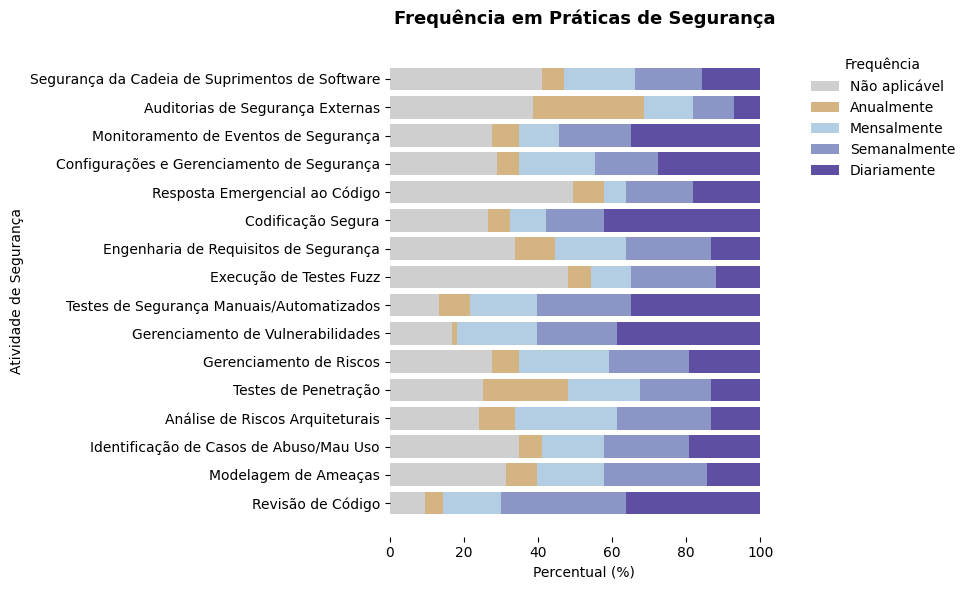

In [164]:
plot_barras(descricao_frequencia, "Frequência em Práticas de Segurança")

In [165]:
descricao_efetividade

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,8,0,4,11,24,36
Modelagem de Ameaças,18,1,3,11,21,29
Identificação de Casos de Abuso/Mau Uso,14,1,6,19,20,23
Análise de Riscos Arquiteturais,12,1,2,12,24,32
Testes de Penetração,14,0,3,7,20,39
Gerenciamento de Riscos,14,1,3,6,26,33
Gerenciamento de Vulnerabilidades,10,0,3,12,18,40
Testes de Segurança Manuais/Automatizados,10,1,2,14,23,33
Execução de Testes Fuzz,24,3,12,18,13,13
Engenharia de Requisitos de Segurança,14,0,2,11,28,28


In [166]:
descricao_efetividade.div(descricao_efetividade.sum(axis=1), axis=0) * 100

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,9.638554,0.000000,4.819277,13.253012,28.915663,43.373494
Modelagem de Ameaças,21.686747,1.204819,3.614458,13.253012,25.301205,34.939759
Identificação de Casos de Abuso/Mau Uso,16.867470,1.204819,7.228916,22.891566,24.096386,27.710843
Análise de Riscos Arquiteturais,14.457831,1.204819,2.409639,14.457831,28.915663,38.554217
Testes de Penetração,16.867470,0.000000,3.614458,8.433735,24.096386,46.987952
Gerenciamento de Riscos,16.867470,1.204819,3.614458,7.228916,31.325301,39.759036
Gerenciamento de Vulnerabilidades,12.048193,0.000000,3.614458,14.457831,21.686747,48.192771
Testes de Segurança Manuais/Automatizados,12.048193,1.204819,2.409639,16.867470,27.710843,39.759036
Execução de Testes Fuzz,28.915663,3.614458,14.457831,21.686747,15.662651,15.662651
Engenharia de Requisitos de Segurança,16.867470,0.000000,2.409639,13.253012,33.734940,33.734940


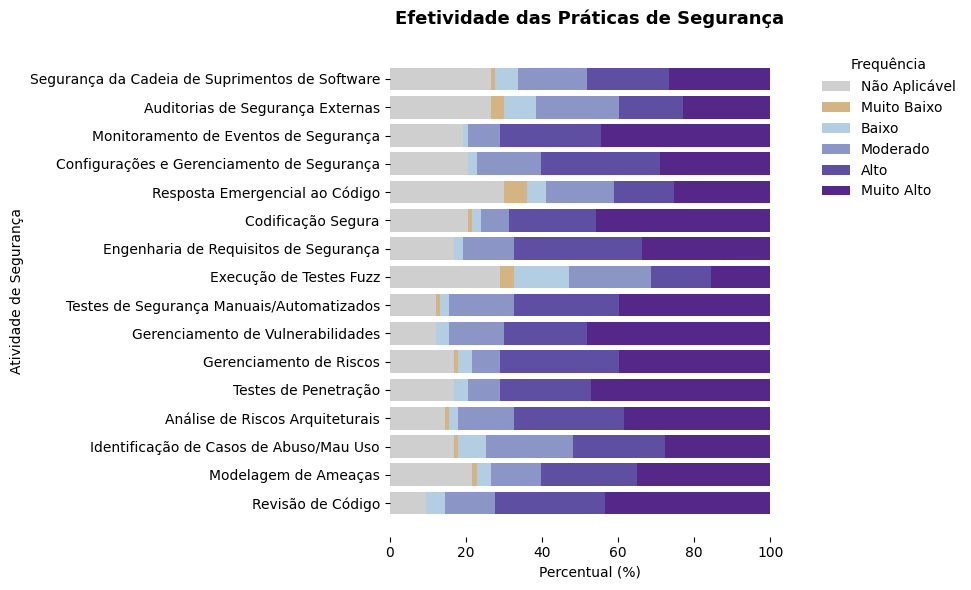

In [167]:
plot_barras(descricao_efetividade, "Efetividade das Práticas de Segurança")

In [168]:
descricao_facilidade

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,11,2,9,26,17,18
Modelagem de Ameaças,20,2,13,24,16,8
Identificação de Casos de Abuso/Mau Uso,18,4,11,35,11,4
Análise de Riscos Arquiteturais,14,6,19,19,19,6
Testes de Penetração,15,7,14,21,12,14
Gerenciamento de Riscos,18,4,11,29,15,6
Gerenciamento de Vulnerabilidades,13,2,7,31,14,16
Testes de Segurança Manuais/Automatizados,13,4,11,21,21,13
Execução de Testes Fuzz,28,3,13,19,12,8
Engenharia de Requisitos de Segurança,20,2,13,21,25,2


In [169]:
descricao_facilidade.div(descricao_facilidade.sum(axis=1), axis=0) * 100

,Não Aplicável,Muito Baixo,Baixo,Moderado,Alto,Muito Alto
Revisão de Código,13.253012,2.409639,10.843373,31.325301,20.481928,21.686747
Modelagem de Ameaças,24.096386,2.409639,15.662651,28.915663,19.277108,9.638554
Identificação de Casos de Abuso/Mau Uso,21.686747,4.819277,13.253012,42.168675,13.253012,4.819277
Análise de Riscos Arquiteturais,16.867470,7.228916,22.891566,22.891566,22.891566,7.228916
Testes de Penetração,18.072289,8.433735,16.867470,25.301205,14.457831,16.867470
Gerenciamento de Riscos,21.686747,4.819277,13.253012,34.939759,18.072289,7.228916
Gerenciamento de Vulnerabilidades,15.662651,2.409639,8.433735,37.349398,16.867470,19.277108
Testes de Segurança Manuais/Automatizados,15.662651,4.819277,13.253012,25.301205,25.301205,15.662651
Execução de Testes Fuzz,33.734940,3.614458,15.662651,22.891566,14.457831,9.638554
Engenharia de Requisitos de Segurança,24.096386,2.409639,15.662651,25.301205,30.120482,2.409639


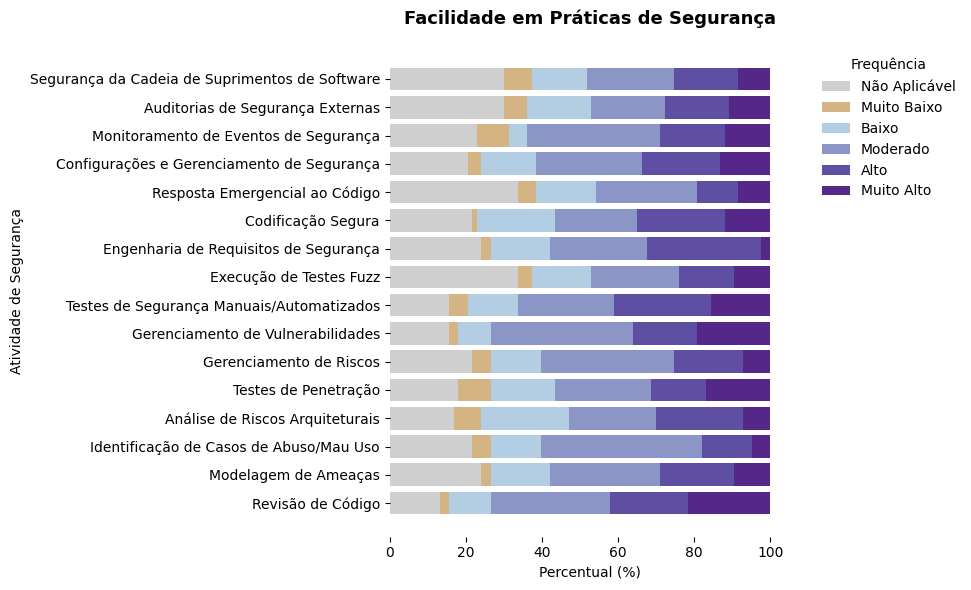

In [170]:
plot_barras(descricao_facilidade, "Facilidade em Práticas de Segurança")

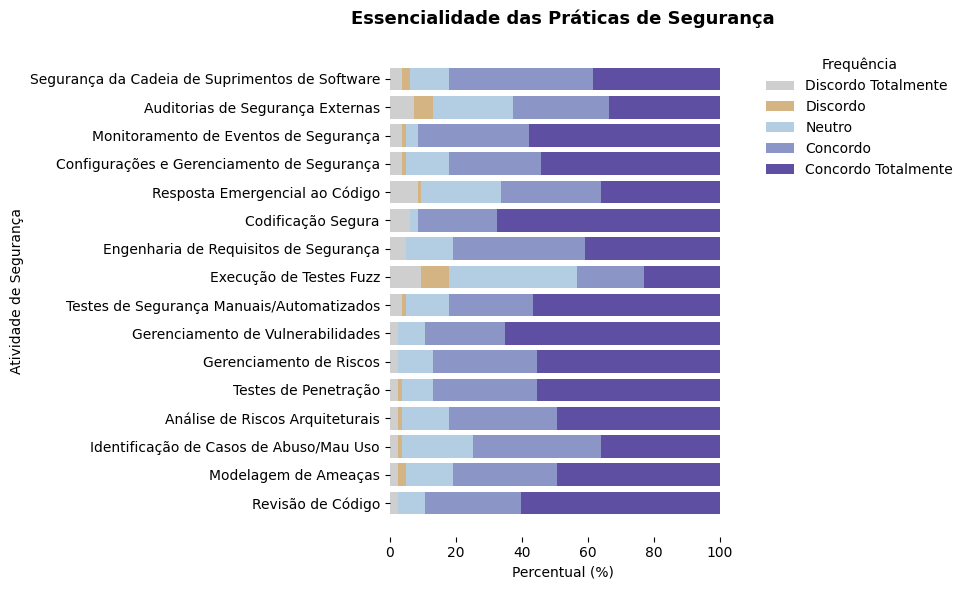

In [171]:
plot_barras(descricao_essencialidade,  "Essencialidade das Práticas de Segurança")

In [172]:
df[colunas_essencialidade[0]].unique()

array(['Concordo', 'Concordo Totalmente', 'Neutro', 'Discordo Totalmente'],
      dtype=object)

In [173]:
for coluna in colunas_frequencia:
  df[coluna] = df[coluna].map(frequencia_map)

for coluna in colunas_efetividade:
  df[coluna] = df[coluna].map(efetividade_map)

for coluna in colunas_facilidade:
  df[coluna] = df[coluna].map(facilidade_map)

for coluna in colunas_essencialidade:
  df[coluna] = df[coluna].map(essencialidade_map)

In [174]:
df['Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'].unique()

array(['Entre 7 e 14 anos', 'Entre 4 e 5 anos', 'Entre 1 e 3 anos',
       'Menos de 1 ano', 'Mais de 15 anos'], dtype=object)

In [175]:
coluna_experiencia = 'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'
coluna_anos_experiencia_dev = 'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'
coluna_anos_experiencia_seg = 'Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?'
coluna_nivel_educacao = 'Qual é o seu nível de educação formal concluída?'
coluna_senioridade = 'Por favor, indique a senioridade da posição que ocupa.'
coluna_especialistas = 'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?'
coluna_certificacao = 'Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?'

tem_experiencia = 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.'

resposta_especialistas = ["Cryptographer", "Penetration tester", "DevOps engineer", "Privacy engineer", "Security engineer"]
resposta_nao_certificacao = ["Não possui nenhuma certificação"]
certificacoes_nao_seguranca = ["SCRUM", "AWS", "AWS Practitioner", "Azure", "CASE", "CASE Java", "AWS e Azure", "Não possui nenhuma certificação"]

In [176]:
df["Numero De Certificações em Segurança"] = (
    df[coluna_certificacao]
    .fillna("")  
    .str.split(",")  # divide listas
    .apply(lambda certs: sum(
        c.strip() not in certificacoes_nao_seguranca  # remove espaços e verifica
        for c in certs
    ))
)


In [177]:
df[[coluna_certificacao, "Numero De Certificações em Segurança"]]

,"Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?",Numero De Certificações em Segurança
1,Não possui nenhuma certificação,0
2,Não possui nenhuma certificação,0
3,Não possui nenhuma certificação,0
4,eWPTX,1
5,"Certified Ethical Hacker (CEH), CompTIA Security+",2
6,Não possui nenhuma certificação,0
7,Não possui nenhuma certificação,0
9,"DCPT, ISO 27001",2
10,Não possui nenhuma certificação,0
11,Não possui nenhuma certificação,0


In [178]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[coluna_senioridade].unique())
print(df[coluna_anos_experiencia_dev].unique())
print(df[coluna_anos_experiencia_seg].unique())


['Mestrado' 'Estudante de Doutorado' 'Ensino Superior' 'Doutorado'
 'Especialização' 'Ensino Médio' 'Estudante de Mestrado']
['Sênior (10+ anos)' 'Júnior (até 5 anos)' 'Pleno (6 a 9 anos)'
 'Estagiário']
['Entre 7 e 14 anos' 'Entre 4 e 5 anos' 'Entre 1 e 3 anos'
 'Menos de 1 ano' 'Mais de 15 anos']
['Entre 7 e 14 anos' 'Nenhuma' 'Entre 1 e 3 anos' 'Entre 4 e 6 anos'
 'Menos de 1 ano' 'Mais de 15 anos']


In [179]:
len(df[~df[coluna_especialistas].isin(resposta_especialistas)][coluna_especialistas].unique())

39

In [180]:
df[~df[coluna_especialistas].isin(resposta_especialistas)][coluna_especialistas].unique()

array(['Penetration tester, Security engineer',
       'Developer (Backend, frontend, fullstack)',
       'Penetration tester, Requirements Engineer, Security engineer',
       'DevOps engineer, Solution Architect',
       'Privacy engineer, Security engineer',
       'DevOps engineer, Privacy engineer, Security engineer',
       'Solution Architect, Test Manager / Tester', 'SOC',
       'Gerente de Segurança da Informação', 'Application secure',
       'Security Analyst',
       'Developer (Backend, frontend, fullstack), DevOps engineer, Security engineer, Solution Architect',
       'Appsec', 'Penetration tester, DevOps engineer, Security engineer',
       'Penetration tester, DevOps engineer, Security engineer, Solution Architect',
       'Penetration tester, DevOps engineer', 'Solution Architect',
       'Cybersegurança',
       'Data Scientist, Developer (Backend, frontend, fullstack), Penetration tester, DevOps engineer, Product owner, Project Lead / Project Manager, Security eng

In [181]:
print("Quantidade de especialistas:", df[df[coluna_especialistas].isin(resposta_especialistas)].shape[0])
print("Quantidade de não especialistas:", df[~df[coluna_especialistas].isin(resposta_especialistas)].shape[0])

Quantidade de especialistas: 26
Quantidade de não especialistas: 57


In [182]:
df_exp_direta = df[df[coluna_experiencia] == tem_experiencia]
df_exp_indireta = df[df[coluna_experiencia] != tem_experiencia]

df_exp_direta.shape

(62, 103)

In [183]:
df[coluna_senioridade].unique()

array(['Sênior (10+ anos)', 'Júnior (até 5 anos)', 'Pleno (6 a 9 anos)',
       'Estagiário'], dtype=object)

In [184]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[coluna_senioridade].unique())
print(df[coluna_anos_experiencia_dev].unique())
print(df[coluna_anos_experiencia_seg].unique())


['Mestrado' 'Estudante de Doutorado' 'Ensino Superior' 'Doutorado'
 'Especialização' 'Ensino Médio' 'Estudante de Mestrado']
['Sênior (10+ anos)' 'Júnior (até 5 anos)' 'Pleno (6 a 9 anos)'
 'Estagiário']
['Entre 7 e 14 anos' 'Entre 4 e 5 anos' 'Entre 1 e 3 anos'
 'Menos de 1 ano' 'Mais de 15 anos']
['Entre 7 e 14 anos' 'Nenhuma' 'Entre 1 e 3 anos' 'Entre 4 e 6 anos'
 'Menos de 1 ano' 'Mais de 15 anos']


In [185]:
nivel_educacao_map = {
    'Ensino Médio': 1,
    'Ensino Superior': 2,
    'Especialização': 3,
    'Estudante de Mestrado':4,
    'Mestrado': 5,
    'Estudante de Doutorado': 6,
    'Doutorado': 7
}

senioridade_map = {
    'Estagiário': 1,
    'Júnior (até 5 anos)': 2,
    'Pleno (6 a 9 anos)': 3,
    'Sênior (10+ anos)': 4
}

anos_exp_dev_map ={
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 5 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

anos_exp_seg_map = {
    'Nenhuma' : 0,
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 6 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

def interacao_exp_direta_especialista(row):
    if row['especialista'] and row['experiencia_direta']:
        return 3
    elif row['experiencia_direta'] and not row['especialista']:
        return 2
    else:
        return 1


def relacao_exp_direta_especialista(row):
    return (row['especialista'] + row['experiencia_direta'])/2

df[coluna_anos_experiencia_dev] = df[coluna_anos_experiencia_dev].map(anos_exp_dev_map)

df[coluna_senioridade] = df[coluna_senioridade].map(senioridade_map)

df[coluna_anos_experiencia_seg] = df[coluna_anos_experiencia_seg].map(anos_exp_seg_map)

df['especialista'] = df[coluna_especialistas].apply(lambda x: 1 if x in resposta_especialistas else 0)

df['experiencia_direta'] = df[coluna_experiencia].apply(lambda x: 1 if x == tem_experiencia else 0)

df['certificacao'] = df[coluna_certificacao].apply(lambda x: 0 if x in resposta_nao_certificacao else 1)

df['Qual é o seu nível de educação formal concluída?'] = df['Qual é o seu nível de educação formal concluída?'].map(nivel_educacao_map)

df['interacao_exp_direta_especialista'] = df.apply(interacao_exp_direta_especialista, axis=1)

df['relacao_exp_direta_especialista'] = df.apply(relacao_exp_direta_especialista, axis=1)

In [186]:
print(df['Qual é o seu nível de educação formal concluída?'].unique())
print(df[coluna_senioridade].unique())
print(df[coluna_anos_experiencia_dev].unique())
print(df[coluna_anos_experiencia_seg].unique())

[5 6 2 7 3 1 4]
[4 2 3 1]
[4 3 2 1 5]
[4 0 2 3 1 5]


In [187]:
df['especialista'].sum()

np.int64(26)

In [188]:
print("Total:",df.shape[0])
print(f"Porcentagem de experiencia direta: {(df_exp_direta.shape[0]/ df.shape[0])*100:.3f}%")
print(f"Porcentagem de experiencia indireta: {(df_exp_indireta.shape[0]/ df.shape[0])*100:.3f}%")

Total: 83
Porcentagem de experiencia direta: 74.699%
Porcentagem de experiencia indireta: 25.301%


In [189]:
df['relacao_exp_direta_especialista'].value_counts()

relacao_exp_direta_especialista
0.5    46
1.0    21
0.0    16
Name: count, dtype: int64

In [190]:
df_frequencia = df[colunas_frequencia].copy()
df_facilidade = df[colunas_facilidade].copy()
df_efetividade = df[colunas_efetividade].copy()
df_essencialidade = df[colunas_essencialidade].copy()

In [191]:
nivel_educacao = df['Qual é o seu nível de educação formal concluída?']
anos_exp_dev = df['Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?']
anos_exp_seg = df['Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?']
senioridade = df['Por favor, indique a senioridade da posição que ocupa.']
interacao_exp_direta_especialista_col = df['interacao_exp_direta_especialista']
relacao_exp_direta_especialista_col = df['relacao_exp_direta_especialista']
qtd_certificacao_seguranca = df["Numero De Certificações em Segurança"]

# formula peso 1
# df['peso'] = (0.3*nivel_educacao)+(0.25*anos_exp_dev)+(0.2*senioridade)+(0.25*interacao_exp_direta_especialista_col)

# formula peso 2
#df_final['peso'] = (nivel_educacao/nivel_educacao.nunique()) + (anos_exp_dev/anos_exp_dev.median()) + (senioridade/senioridade.median()) + relacao_exp_direta_especialista_col
df['peso'] = (nivel_educacao/nivel_educacao.nunique()) + qtd_certificacao_seguranca + (anos_exp_dev/anos_exp_dev.median()) + (anos_exp_seg/anos_exp_seg.median()) + (senioridade/senioridade.median()) + relacao_exp_direta_especialista_col 


total_values_facilidade = {}
total_values_frequencia = {}
total_values_efetividade = {}
total_values_essencialidade = {}

total_values_facilidade_normalized = {}
total_values_frequencia_normalized = {}
total_values_efetividade_normalized = {}
total_values_essencialidade_normalized = {}


for coluna in df.columns:
      df_sem_na_col = df[df[coluna] != 0] # remover os not applicable
      if coluna in colunas_frequencia:
            print(f"Frequencia ({col}):", df_sem_na_col['peso'].sum())
            total_values_frequencia[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum()
            total_values_frequencia_normalized[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum() / (df_sem_na_col['peso'].sum()*4)

      if coluna in colunas_facilidade:
            print(f"Facilidade: ({col})", df_sem_na_col['peso'].sum())
            total_values_facilidade[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum()
            total_values_facilidade_normalized[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum() / (df_sem_na_col['peso'].sum()*5)

      if coluna in colunas_efetividade:
            print(f"efetividade: ({col})", df_sem_na_col['peso'].sum())
            total_values_efetividade[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum()
            total_values_efetividade_normalized[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum() / (df_sem_na_col['peso'].sum()*5)

      if coluna in colunas_essencialidade:
            print(f"essencialidade ({col}):", df_sem_na_col['peso'].sum())
            total_values_essencialidade[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum()
            total_values_essencialidade_normalized[coluna] = (df_sem_na_col[coluna] * df_sem_na_col['peso']).sum() / (df_sem_na_col['peso'].sum()*5)

for coluna in df.columns:
    if coluna in colunas_facilidade + colunas_efetividade + colunas_frequencia + colunas_essencialidade:
        df[coluna] = df[coluna] * df['peso']

Frequencia (Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]): 344.6904761904762
Frequencia (Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprimentos de Software]): 280.9761904761904
Frequencia (Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Segurança da Cadeia de Suprime

In [192]:
medias = []

for col in df_efetividade.columns:
    medias.append(df_efetividade.loc[df_efetividade[col].isin([1, 2, 3, 4, 5]).values, col].mean())

In [193]:
total_values_frequencia

{'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.float64(1074.1190476190475),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.float64(769.2857142857142),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.float64(787.8333333333334),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]': np.float64(814.2857142857142),
 'Co

In [194]:
df['peso'].sum()

np.float64(381.76190476190476)

In [195]:
total_values_efetividade_normalized

{'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.float64(0.8273348519362188),
 'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.float64(0.8170323928944617),
 'Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.7491962805449434),
 'Com base e

In [196]:
total_values_facilidade_normalized

{'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Revisão de Código]': np.float64(0.7118189073496337),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Modelagem de Ameaças]': np.float64(0.6449399922570654),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza.  [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.6179581795817959),
 'Com base em sua experiência, como você avaliaria o nível de facilidade de uso das seguintes práticas de segurança de software? Considere marcar “Não Aplicável” para as práticas das quais 

In [197]:
total_values_frequencia_normalized

{'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código]': np.float64(0.7790460730814394),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças]': np.float64(0.68447589187357),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.740710064469914),
 'Com que frequência você costuma aplicar as seguintes práticas de segurança de software  em seus projetos? Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Análise de Riscos Arquiteturais]': np.float64(0.6539196940726577),
 'Co

In [198]:
total_values_essencialidade_normalized

{'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Revisão de Código]': np.float64(0.8899463639765498),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Modelagem de Ameaças]': np.float64(0.8530497692403641),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Identificação de Casos de Abuso/Mau Uso]': np.float64(0.8081077709866533),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Análise de Riscos Arquiteturais]': np.float64(0.8540476487464138),
 'Qual a sua opinião quanto a frase a seguir aplicada em cada uma das práticas abaixo:“Essa prática é essencial para a proteção do sistema.” [Testes de Penetração]': np.float64(0.88

In [199]:
print(len(total_values_efetividade_normalized))
print(len(total_values_facilidade_normalized))
print(len(total_values_frequencia_normalized))
print(len(total_values_essencialidade_normalized))

16
16
16
16


In [200]:
facilidade_normalized_df = pd.DataFrame({
    'Categoria': [e.replace('[', '').replace(']', '') for e in praticas],
    'Facilidade': list(total_values_facilidade_normalized.values())
})

efetividade_normalized_df = pd.DataFrame({
    'Categoria': [e.replace('[', '').replace(']', '') for e in praticas],
    'Efetividade': list(total_values_efetividade_normalized.values())
})

frequencia_normalized_df = pd.DataFrame({
    'Categoria': [e.replace('[', '').replace(']', '') for e in praticas],
    'Frequencia': list(total_values_frequencia_normalized.values())
})

essencialidade_normalized_df = pd.DataFrame({
    'Categoria': [e.replace('[', '').replace(']', '') for e in praticas],
    'Essencialidade': list(total_values_essencialidade_normalized.values())
})

In [201]:
def bold_text(val):
    return 'font-weight: bold'

def apply_percent(x):
    return f'{x*100:.2f}%'

final = facilidade_normalized_df.merge(efetividade_normalized_df, on='Categoria').merge(frequencia_normalized_df, on='Categoria').merge(essencialidade_normalized_df, on='Categoria')

from pathlib import Path
results_path = Path('results')
results_path.mkdir(exist_ok=True)

final.to_excel(results_path / 'final.xlsx')

final.style.background_gradient(cmap='RdYlGn', low=0.3, high=0.4).map(bold_text)

,Categoria,Facilidade,Efetividade,Frequencia,Essencialidade
0,Revisão de Código,0.711819,0.827335,0.779046,0.889946
1,Modelagem de Ameaças,0.644940,0.817032,0.684476,0.853050
2,Identificação de Casos de Abuso/Mau Uso,0.617958,0.749196,0.740710,0.808108
3,Análise de Riscos Arquiteturais,0.613141,0.817950,0.653920,0.854048
4,Testes de Penetração,0.642370,0.879404,0.591110,0.887689
5,Gerenciamento de Riscos,0.623149,0.840651,0.694755,0.877835
6,Gerenciamento de Vulnerabilidades,0.704160,0.853873,0.814044,0.899389
7,Testes de Segurança Manuais/Automatizados,0.682587,0.821981,0.758843,0.865436
8,Execução de Testes Fuzz,0.626588,0.652547,0.696384,0.670138
9,Engenharia de Requisitos de Segurança,0.633173,0.814941,0.670668,0.827280


In [202]:
df['relacao_exp_direta_especialista'].isna().sum()

np.int64(0)

In [203]:
df_facilidade_com_peso = df[colunas_facilidade].copy()
df_efetividade_com_peso = df[colunas_efetividade].copy()
df_frequencia_com_peso = df[colunas_frequencia].copy()
df_essencialidade_com_peso = df[colunas_essencialidade].copy()

In [204]:
# caso seja 1 ou 2, diz se que o uso não é facil
def facilidade_converting(x):
  return 0 if x == 1 or x == 2 else 1

# caso seja 4 ou 5, diz-se que tem efetividade
def efetividade_converting(x):
    return 0 if x == 1 or x == 2 or x == 3 else 1

df_facilidade_converted = df_facilidade.copy()
df_efetividade_converted = df_efetividade.copy()

for coluna in df_facilidade.columns:
    df_facilidade_converted.loc[:, f'{coluna}'] = df_facilidade.loc[:, coluna].apply(facilidade_converting).copy()

for coluna in df_efetividade.columns:
    df_efetividade_converted.loc[:, f'{coluna}'] = df_efetividade.loc[:, coluna].apply(efetividade_converting).copy()

In [205]:
efetivi = []
facili = []

for i in range(len(df_facilidade.columns)):
  pratic = praticas[i]

  df_facilidade_pratica_converted = df_facilidade_converted.iloc[:, i]
  df_efetividade_pratica_converted = df_efetividade_converted.iloc[:, i]

  facil = df_facilidade_pratica_converted.sum() / len(df_facilidade_pratica_converted)
  efeti = df_efetividade_pratica_converted.sum() / len(df_efetividade_pratica_converted)

  facili.append(facil)
  efetivi.append(efeti)

percents_df = pd.DataFrame({
    'Praticas': [e.replace('[', '').replace(']', '') for e in praticas],
    'Facilidade': facili,
    'Efetividade': efetivi
})

In [206]:
percents_df = percents_df.set_index('Praticas')

In [207]:
percents_df.style.background_gradient(cmap='RdYlGn', low=0.3, high=0.4).map(bold_text)

,Facilidade,Efetividade
Praticas,,
Revisão de Código,0.867470,0.819277
Modelagem de Ameaças,0.819277,0.819277
Identificação de Casos de Abuso/Mau Uso,0.819277,0.686747
Análise de Riscos Arquiteturais,0.698795,0.819277
Testes de Penetração,0.746988,0.879518
Gerenciamento de Riscos,0.819277,0.879518
Gerenciamento de Vulnerabilidades,0.891566,0.819277
Testes de Segurança Manuais/Automatizados,0.819277,0.795181
Execução de Testes Fuzz,0.807229,0.602410


In [208]:
for pratica in colunas_efetividade:
    quant = []  # lista de índices com valor 0 para a prática atual
    for i in range(len(df)):
        if df.iloc[i][pratica] == 0:
            quant.append(i)
    print(f"Prática: {pratica} -> Índices com valor 0: {quant} (Total: {len(quant)})")

Prática: Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Revisão de Código] -> Índices com valor 0: [22, 24, 30, 51, 60, 72, 73, 77] (Total: 8)
Prática: Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para as práticas das quais você não utiliza. [Modelagem de Ameaças] -> Índices com valor 0: [1, 17, 21, 22, 24, 26, 30, 37, 38, 42, 45, 48, 51, 59, 60, 62, 77, 79] (Total: 18)
Prática: Com base em sua experiência, como você avalia a efetividade das seguintes práticas de segurança de software na prevenção, remoção ou detecção de problemas de segurança em seus projetos?  Considere marcar “Não Aplicável” para

In [209]:
indices = [1, 17, 21, 22, 24, 26, 30, 37, 38, 42, 45, 48, 51, 59, 60, 62, 77]

for i in indices:
    print(df[colunas_efetividade[1]].iloc[i])


0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0


# Correlações

In [210]:
from scipy.stats import spearmanr

def calc_correlations(df_frequencia, df_efetividade, df_facilidade, df_essencialidade):
    correlations_efetividade_frequencia = {}
    correlations_efetividade_facilidade = {}
    correlations_frequencia_facilidade = {}
    correlations_frequencia_essencialidade = {}
    correlations_efetividade_essencialidade = {}
    correlations_facilidade_essencialidade = {}

    p_values_freq_efe = {}
    p_values_efetividade_facilidade = {}
    p_values_frequencia_facilidade = {}
    p_values_frequencia_essencialidade = {}
    p_values_efetividade_essencialidade = {}
    p_values_facilidade_essencialidade = {}
    

    for i in range(len(df_frequencia.columns)):
        pratica = praticas[i]

        df_frequencia_pratica = df_frequencia.iloc[:, i]
        df_efetividade_pratica = df_efetividade.iloc[:, i]
        df_facilidade_pratica = df_facilidade.iloc[:, i]
        df_essencialidade_pratica = df_essencialidade.iloc[:, i]

        correlation_freq_efe, p_value_freq_efe = spearmanr(df_frequencia_pratica, df_efetividade_pratica)
        correlation_freq_facilidade, p_value_freq_facilidade = spearmanr(df_frequencia_pratica, df_facilidade_pratica)
        correlation_efe_facilidade, p_value_efe_facilidade = spearmanr(df_efetividade_pratica, df_facilidade_pratica)
        correlation_freq_ess, p_value_freq_ess = spearmanr(df_frequencia_pratica, df_essencialidade_pratica)
        correlation_efe_ess, p_value_efe_ess = spearmanr(df_efetividade_pratica, df_essencialidade_pratica)
        correlation_facilidade_ess, p_value_facilidade_ess = spearmanr(df_facilidade_pratica, df_essencialidade_pratica)
        

        correlations_efetividade_frequencia[f'Frequência x Efetividade em {pratica}'] = correlation_freq_efe.round(3)
        p_values_freq_efe[f'Frequência x Efetividade em {pratica}'] = p_value_freq_efe

        correlations_efetividade_facilidade[f'Efetividade x Facilidade em {pratica}'] = correlation_efe_facilidade.round(3)
        p_values_efetividade_facilidade[f'Efetividade x Facilidade em {pratica}'] = p_value_efe_facilidade

        correlations_frequencia_facilidade[f'Frequência x Facilidade em {pratica}'] = correlation_freq_facilidade.round(3)
        p_values_frequencia_facilidade[f'Frequência x Facilidade em {pratica}'] = p_value_freq_facilidade

        correlations_frequencia_essencialidade[f'Frequência x Essencialidade em {pratica}'] = correlation_freq_ess.round(3)
        p_values_frequencia_essencialidade[f'Frequência x Essencialidade em {pratica}'] = p_value_freq_ess

        correlations_efetividade_essencialidade[f'Efetividade x Essencialidade em {pratica}'] = correlation_efe_ess.round(3)
        p_values_efetividade_essencialidade[f'Efetividade x Essencialidade em {pratica}'] = p_value_efe_ess

        correlations_facilidade_essencialidade[f'Facilidade x Essencialidade em {pratica}'] = correlation_facilidade_ess.round(3)
        p_values_facilidade_essencialidade[f'Facilidade x Essencialidade em {pratica}'] = p_value_facilidade_ess


    correlations_efetividade_facilidade_df = pd.DataFrame({
        'Categoria': list(correlations_efetividade_facilidade.keys()),
        'Correlação(Efec, Ease)': list(correlations_efetividade_facilidade.values()),
        'p-valor': list(p_values_efetividade_facilidade.values())
    })

    correlations_frequencia_facilidade_df = pd.DataFrame({
        'Categoria': list(correlations_frequencia_facilidade.keys()),
        'Correlação(Use, Ease)': list(correlations_frequencia_facilidade.values()),
        'p-valor': list(p_values_frequencia_facilidade.values())
    })

    correlations_efetividade_frequencia_df = pd.DataFrame({
        'Categoria': list(correlations_efetividade_frequencia.keys()),
        'Correlação(Efec, Use)': list(correlations_efetividade_frequencia.values()),
        'p-valor': list(p_values_freq_efe.values())
    })

    correlations_efetividade_essencialidade_df = pd.DataFrame({
        'Categoria': list(correlations_efetividade_essencialidade.keys()),
        'Correlação(Efec, Essen)': list(correlations_efetividade_essencialidade.values()),
        'p-valor': list(p_values_efetividade_essencialidade.values())
    })

    correlations_facilidade_essencialidade_df = pd.DataFrame({
        'Categoria': list(correlations_facilidade_essencialidade.keys()),
        'Correlação(Ease, Essen)': list(correlations_facilidade_essencialidade.values()),
        'p-valor': list(p_values_facilidade_essencialidade.values())
    })

    correlations_frequencia_essencialidade_df = pd.DataFrame({
        'Categoria': list(correlations_frequencia_essencialidade.keys()),
        'Correlação(Use, Essen)': list(correlations_frequencia_essencialidade.values()),
        'p-valor': list(p_values_frequencia_essencialidade.values())
    })

    def highlight_significant(s):
            return ['font-weight: bold' if v < 0.05 else '' for v in s]

    def highlight_strong_corr(value):
        return 'font-weight: bold' if (value > 0.5 or value < -0.5) else ''

    correlations_efetividade_frequencia_df_styled = correlations_efetividade_frequencia_df.style.map(highlight_strong_corr, subset=['Correlação(Efec, Use)'])
    correlations_efetividade_frequencia_df = correlations_efetividade_frequencia_df_styled.apply(highlight_significant, subset=['p-valor'])

    correlations_efetividade_facilidade_df_styled = correlations_efetividade_facilidade_df.style.map(highlight_strong_corr, subset=['Correlação(Efec, Ease)'])
    correlations_efetividade_facilidade_df = correlations_efetividade_facilidade_df_styled.apply(highlight_significant, subset=['p-valor'])

    correlations_frequencia_facilidade_df_styled = correlations_frequencia_facilidade_df.style.map(highlight_strong_corr, subset=['Correlação(Use, Ease)'])
    correlations_frequencia_facilidade_df = correlations_frequencia_facilidade_df_styled.apply(highlight_significant, subset=['p-valor'])

    correlations_frequencia_essencialidade_df_styled = correlations_frequencia_essencialidade_df.style.map(highlight_strong_corr, subset=['Correlação(Use, Essen)'])
    correlations_frequencia_essencialidade_df = correlations_frequencia_essencialidade_df_styled.apply(highlight_significant, subset=['p-valor'])

    correlation_efe_ess_df_styled = correlations_efetividade_essencialidade_df.style.map(highlight_strong_corr, subset=['Correlação(Efec, Essen)'])
    correlation_efe_ess_df = correlation_efe_ess_df_styled.apply(highlight_significant, subset=['p-valor'])

    correlation_facilidade_ess_df_styled = correlations_facilidade_essencialidade_df.style.map(highlight_strong_corr, subset=['Correlação(Ease, Essen)'])
    correlation_facilidade_ess_df = correlation_facilidade_ess_df_styled.apply(highlight_significant, subset=['p-valor'])


    return correlations_efetividade_frequencia_df, correlations_efetividade_facilidade_df, correlations_frequencia_facilidade_df, correlations_frequencia_essencialidade_df, correlation_efe_ess_df, correlation_facilidade_ess_df

In [211]:
correlations_efetividade_frequencia_df, correlations_efetividade_facilidade_df, correlations_frequencia_facilidade_df, correlations_frequencia_essencialidade_df, correlation_efe_ess_df, correlation_facilidade_ess_df = calc_correlations(df_frequencia_com_peso, df_efetividade_com_peso, df_facilidade_com_peso, df_essencialidade_com_peso)

In [212]:
correlations_efetividade_frequencia_df

,Categoria,"Correlação(Efec, Use)",p-valor
0,Frequência x Efetividade em [Revisão de Código],0.737000,0.000000
1,Frequência x Efetividade em [Modelagem de Ameaças],0.669000,0.000000
2,Frequência x Efetividade em [Identificação de Casos de Abuso/Mau Uso],0.695000,0.000000
3,Frequência x Efetividade em [Análise de Riscos Arquiteturais],0.645000,0.000000
4,Frequência x Efetividade em [Testes de Penetração],0.694000,0.000000
5,Frequência x Efetividade em [Gerenciamento de Riscos],0.615000,0.000000
6,Frequência x Efetividade em [Gerenciamento de Vulnerabilidades],0.691000,0.000000
7,Frequência x Efetividade em [Testes de Segurança Manuais/Automatizados],0.722000,0.000000
8,Frequência x Efetividade em [Execução de Testes Fuzz],0.655000,0.000000
9,Frequência x Efetividade em [Engenharia de Requisitos de Segurança],0.563000,0.000000


In [213]:
correlations_efetividade_facilidade_df

,Categoria,"Correlação(Efec, Ease)",p-valor
0,Efetividade x Facilidade em [Revisão de Código],0.766000,0.000000
1,Efetividade x Facilidade em [Modelagem de Ameaças],0.779000,0.000000
2,Efetividade x Facilidade em [Identificação de Casos de Abuso/Mau Uso],0.703000,0.000000
3,Efetividade x Facilidade em [Análise de Riscos Arquiteturais],0.755000,0.000000
4,Efetividade x Facilidade em [Testes de Penetração],0.737000,0.000000
5,Efetividade x Facilidade em [Gerenciamento de Riscos],0.714000,0.000000
6,Efetividade x Facilidade em [Gerenciamento de Vulnerabilidades],0.729000,0.000000
7,Efetividade x Facilidade em [Testes de Segurança Manuais/Automatizados],0.685000,0.000000
8,Efetividade x Facilidade em [Execução de Testes Fuzz],0.732000,0.000000
9,Efetividade x Facilidade em [Engenharia de Requisitos de Segurança],0.701000,0.000000


In [214]:
correlations_frequencia_facilidade_df

,Categoria,"Correlação(Use, Ease)",p-valor
0,Frequência x Facilidade em [Revisão de Código],0.702000,0.000000
1,Frequência x Facilidade em [Modelagem de Ameaças],0.731000,0.000000
2,Frequência x Facilidade em [Identificação de Casos de Abuso/Mau Uso],0.725000,0.000000
3,Frequência x Facilidade em [Análise de Riscos Arquiteturais],0.730000,0.000000
4,Frequência x Facilidade em [Testes de Penetração],0.750000,0.000000
5,Frequência x Facilidade em [Gerenciamento de Riscos],0.600000,0.000000
6,Frequência x Facilidade em [Gerenciamento de Vulnerabilidades],0.739000,0.000000
7,Frequência x Facilidade em [Testes de Segurança Manuais/Automatizados],0.627000,0.000000
8,Frequência x Facilidade em [Execução de Testes Fuzz],0.812000,0.000000
9,Frequência x Facilidade em [Engenharia de Requisitos de Segurança],0.698000,0.000000


In [215]:
correlations_frequencia_essencialidade_df

,Categoria,"Correlação(Use, Essen)",p-valor
0,Frequência x Essencialidade em [Revisão de Código],0.598000,0.000000
1,Frequência x Essencialidade em [Modelagem de Ameaças],0.611000,0.000000
2,Frequência x Essencialidade em [Identificação de Casos de Abuso/Mau Uso],0.623000,0.000000
3,Frequência x Essencialidade em [Análise de Riscos Arquiteturais],0.652000,0.000000
4,Frequência x Essencialidade em [Testes de Penetração],0.742000,0.000000
5,Frequência x Essencialidade em [Gerenciamento de Riscos],0.575000,0.000000
6,Frequência x Essencialidade em [Gerenciamento de Vulnerabilidades],0.675000,0.000000
7,Frequência x Essencialidade em [Testes de Segurança Manuais/Automatizados],0.713000,0.000000
8,Frequência x Essencialidade em [Execução de Testes Fuzz],0.572000,0.000000
9,Frequência x Essencialidade em [Engenharia de Requisitos de Segurança],0.526000,0.000000


In [216]:
correlation_efe_ess_df

,Categoria,"Correlação(Efec, Essen)",p-valor
0,Efetividade x Essencialidade em [Revisão de Código],0.755000,0.000000
1,Efetividade x Essencialidade em [Modelagem de Ameaças],0.711000,0.000000
2,Efetividade x Essencialidade em [Identificação de Casos de Abuso/Mau Uso],0.680000,0.000000
3,Efetividade x Essencialidade em [Análise de Riscos Arquiteturais],0.732000,0.000000
4,Efetividade x Essencialidade em [Testes de Penetração],0.864000,0.000000
5,Efetividade x Essencialidade em [Gerenciamento de Riscos],0.768000,0.000000
6,Efetividade x Essencialidade em [Gerenciamento de Vulnerabilidades],0.855000,0.000000
7,Efetividade x Essencialidade em [Testes de Segurança Manuais/Automatizados],0.847000,0.000000
8,Efetividade x Essencialidade em [Execução de Testes Fuzz],0.752000,0.000000
9,Efetividade x Essencialidade em [Engenharia de Requisitos de Segurança],0.809000,0.000000


In [217]:
correlation_facilidade_ess_df

,Categoria,"Correlação(Ease, Essen)",p-valor
0,Facilidade x Essencialidade em [Revisão de Código],0.664000,0.000000
1,Facilidade x Essencialidade em [Modelagem de Ameaças],0.703000,0.000000
2,Facilidade x Essencialidade em [Identificação de Casos de Abuso/Mau Uso],0.648000,0.000000
3,Facilidade x Essencialidade em [Análise de Riscos Arquiteturais],0.739000,0.000000
4,Facilidade x Essencialidade em [Testes de Penetração],0.738000,0.000000
5,Facilidade x Essencialidade em [Gerenciamento de Riscos],0.674000,0.000000
6,Facilidade x Essencialidade em [Gerenciamento de Vulnerabilidades],0.699000,0.000000
7,Facilidade x Essencialidade em [Testes de Segurança Manuais/Automatizados],0.689000,0.000000
8,Facilidade x Essencialidade em [Execução de Testes Fuzz],0.595000,0.000000
9,Facilidade x Essencialidade em [Engenharia de Requisitos de Segurança],0.663000,0.000000
